# Exploratory Data Analysis - Spam Shield
# Goal is to understand the unified dataset before building features and models.

In [18]:
import matplotlib.pyplot as plt
import pandas as pd

from spam_shield import config

df = pd.read_csv(config.PROCESSED_DATASET_FILE)
print(df.shape)
df.head()

(38681, 4)


,message_id,text_content,label,source
0,1,"Go until jurong point, crazy.. Available only ...",ham,sms
1,2,Ok lar... Joking wif u oni...,ham,sms
2,3,Free entry in 2 a wkly comp to win FA Cup fina...,spam,sms
3,4,U dun say so early hor... U c already then say...,ham,sms
4,5,"Nah I don't think he goes to usf, he lives aro...",ham,sms


In [19]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 38681 entries, 0 to 38680
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   message_id    38681 non-null  int64
 1   text_content  38681 non-null  str  
 2   label         38681 non-null  str  
 3   source        38681 non-null  str  
dtypes: int64(1), str(3)
memory usage: 55.3 MB


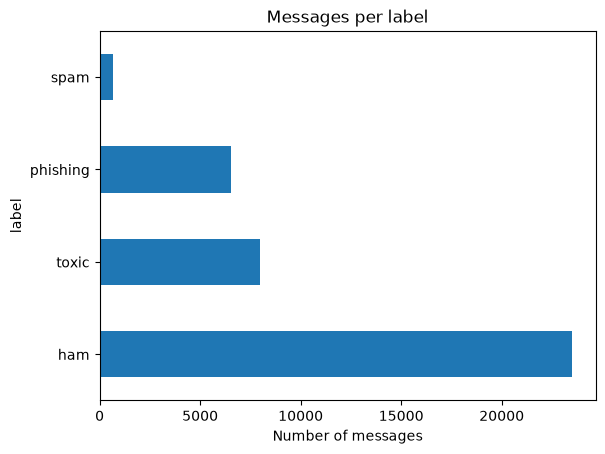

In [20]:
counts = df["label"].value_counts()
ax= counts.plot(kind="barh", title="Messages per label")
ax.set_xlabel("Number of messages")
plt.show()


In [21]:
df["length"] = df["text_content"].str.len()     # number of characters in each message
df.groupby(["source", "label"])["length"].median()

source  label   
chat    ham          213.0
        toxic        132.0
email   ham         1021.0
        phishing     763.0
sms     ham           53.0
        spam         148.0
Name: length, dtype: float64

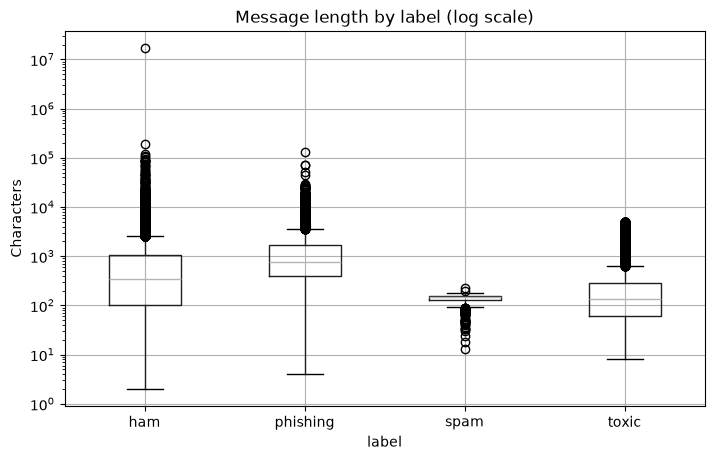

In [22]:
df.boxplot(column="length", by="label", figsize=(8, 5))
plt.yscale("log")
plt.suptitle("")                                  # remove pandas' automatic extra title
plt.title("Message length by label (log scale)")
plt.ylabel("Characters")
plt.show()

In [23]:
for label in config.LABELS:
    print(f"\n===== {label.upper()} =====")
    examples = df[df["label"] == label].sample(3, random_state=1)["text_content"]
    for text in examples:
        print("-", text[:300].replace("\n", " "))   # first 300 chars, newlines flattened


===== HAM =====
- Wow! Great job! Are you going to nominate it for DYK, or should I?
- ":::Of course noone thought he was claiming to be a jelly doughnut. And I trust Slomox, if noone was amused by the ""double-entendre"", noone was. It could be that they didn't expect German so abruptly.  "
- slate's "today's papers": The New York Times and Los Angeles Times both lead with word that a federal judge ruled yesterday that the nation's largest national gas pipeline company, El Paso, illegally withheld gas from the market during California's energy squeeze in 2000-01. The judge concluded that

===== SPAM =====
- FREE entry into our £250 weekly comp just send the word ENTER to 84128 NOW. 18 T&C www.textcomp.com cust care 08712405020.
- 3. You have received your mobile content. Enjoy
- If you don't, your prize will go to another customer. T&C at www.t-c.biz 18+ 150p/min Polo Ltd Suite 373 London W1J 6HL Please call back if busy

===== PHISHING =====
- lose 19 % , powerful weightloss now ava

In [24]:
from sklearn.feature_extraction.text import CountVectorizer


def top_words(texts, n=15):
    """Return the n most frequent words (excluding common English words like 'the')."""
    vectorizer = CountVectorizer(stop_words="english")
    word_counts = vectorizer.fit_transform(texts).sum(axis=0).A1   # total count of each word
    words = vectorizer.get_feature_names_out()
    return pd.Series(word_counts, index=words).nlargest(n)

for label in config.LABELS:
    texts = df.loc[df["label"] == label, "text_content"]
    print(f"{label:>9}: {list(top_words(texts).index)}")

      ham: ['enron', 'language', 'university', 'http', 'com', 'information', 'subject', 'ect', 'new', '00', 'www', 'mail', '10', 'linguistics', 'like']
     spam: ['free', 'txt', 'ur', 'stop', 'text', 'mobile', 'reply', 'claim', 'www', 'prize', 'just', 'cash', 'new', '150p', 'send']
 phishing: ['½ï', 'com', 'email', 'http', 'free', '000', 'mail', 'money', 'company', 'information', 'business', '00', 'time', 'report', 'www']
    toxic: ['fuck', 'shit', 'wikipedia', 'like', 'fucking', 'suck', 'ass', 'die', 'just', 'don', 'know', 'gay', 'page', 'nigger', 'wiki']


In [25]:
df["url_count"] = df["text_content"].str.count(r"https?://|www\.")
df.groupby("label")["url_count"].mean()

label
ham         0.740466
phishing    0.448571
spam        0.151090
toxic       0.041625
Name: url_count, dtype: float64

In [26]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline

# A tiny pipeline: count words → logistic regression (a simple classifier)
source_model = make_pipeline(CountVectorizer(), LogisticRegression(max_iter=1000))

# Train and test 3 times on different splits of the data, then average the scores
scores = cross_val_score(source_model, df["text_content"], df["source"], cv=3)
print(f"Accuracy predicting SOURCE from text alone: {scores.mean():.3f}")

Accuracy predicting SOURCE from text alone: 0.931


In [27]:
# What FRACTION of messages in each label contain at least one URL?
(df["url_count"] > 0).groupby(df["label"]).mean()

label
ham         0.153813
phishing    0.114168
spam        0.133956
toxic       0.016000
Name: url_count, dtype: float64

In [28]:
# What fraction of each label contains these suspicious tokens?
for token in ["enron", "wikipedia", "ï"]:
    share = df["text_content"].str.contains(token, case=False, regex=False).groupby(df["label"]).mean()
    print(f"\n'{token}':\n{share.round(3)}")


'enron':
label
ham         0.097
phishing    0.000
spam        0.000
toxic       0.000
Name: text_content, dtype: float64

'wikipedia':
label
ham         0.059
phishing    0.000
spam        0.000
toxic       0.137
Name: text_content, dtype: float64

'ï':
label
ham         0.003
phishing    0.015
spam        0.000
toxic       0.000
Name: text_content, dtype: float64
